# Brightness sensitivity maps and array scaling

Because the stellar electron rate scales exactly as $10^{-0.4 m}$, the ETC can evaluate SNR on a
(magnitude x exposure time) grid and solve the limiting magnitude **analytically** per bin.
This notebook builds the sensitivity maps for both instruments and shows how they move with the
number of telescopes, which is not yet fixed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

## Bench: SNR per resel as a function of V magnitude and exposure time

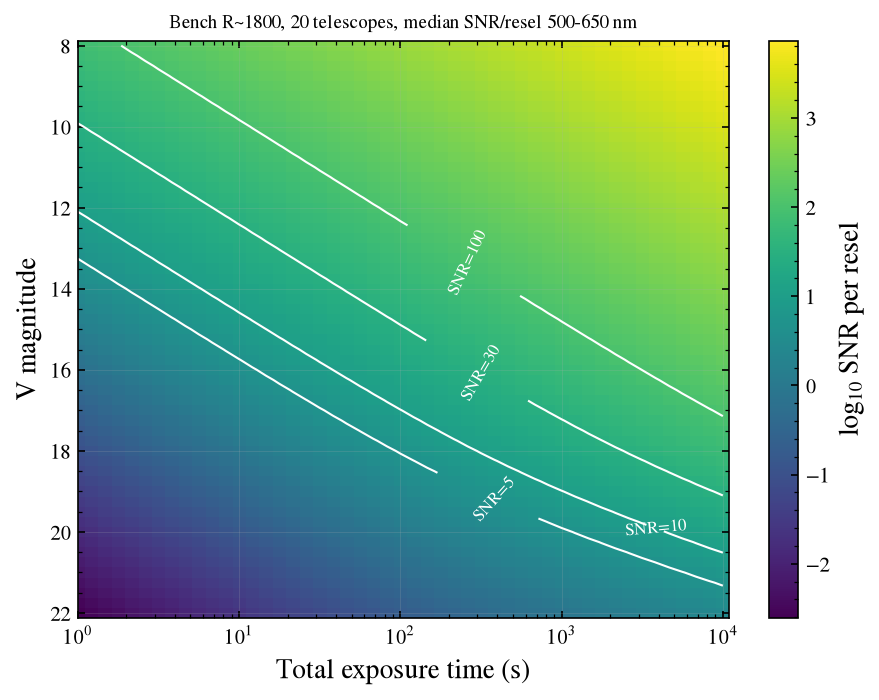

In [2]:
bench = LFASTETC("bench_r1800", n_telescopes=20)
gstar = Source.blackbody(5800, mag=0, band="V")   # the magnitude here is irrelevant for the grid
mags = np.linspace(8, 22, 57)
exps = np.logspace(0, 4, 49)                     # 1 s .. ~3 h
snr = bench.snr_grid(gstar, mags, exps, wavelength=(500, 650))
plot_snr_map(mags, exps, snr, band="V", title="Bench R~1800, 20 telescopes, median SNR/resel 500-650 nm");

## CSHELL: SNR per resel vs H magnitude (R = 18,000 native mode, 1.55-1.56 um)

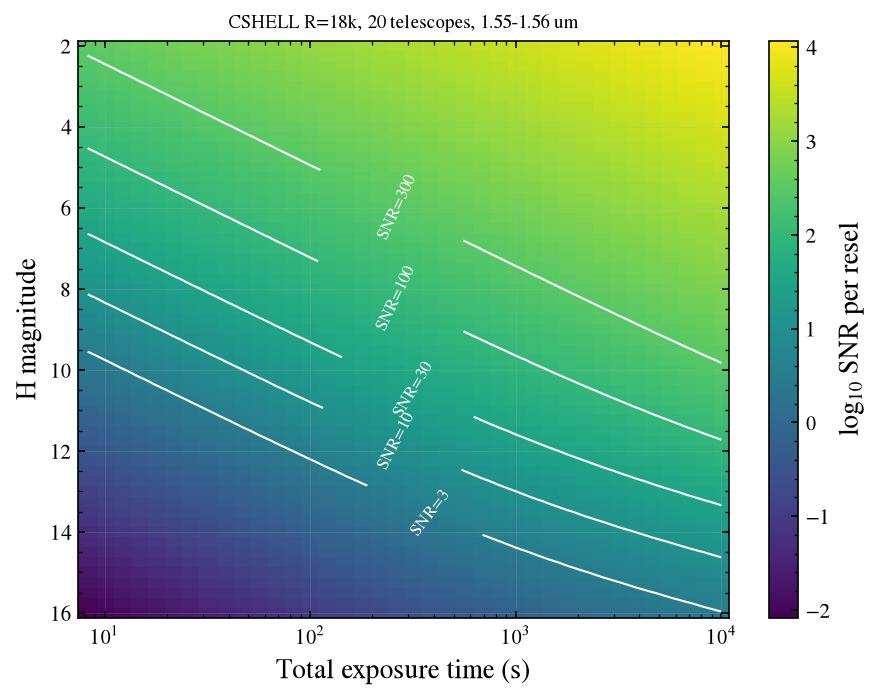

In [3]:
cshell = LFASTETC("cshell_r18000", n_telescopes=20, wavelength_min_nm=1550, wavelength_max_nm=1560)
kstar = Source.blackbody(4500, mag=0, band="H")
mags_h = np.linspace(2, 16, 57)
exps_h = exps[exps >= cshell.instrument.min_exptime]        # CSHELL Fowler-sampling minimum (8 s)
snr_h = cshell.snr_grid(kstar, mags_h, exps_h, wavelength=(1550, 1560))
plot_snr_map(mags_h, exps_h, snr_h, band="H", levels=(3, 10, 30, 100, 300),
             title="CSHELL R=18k, 20 telescopes, 1.55-1.56 um");

## Limiting magnitude versus wavelength

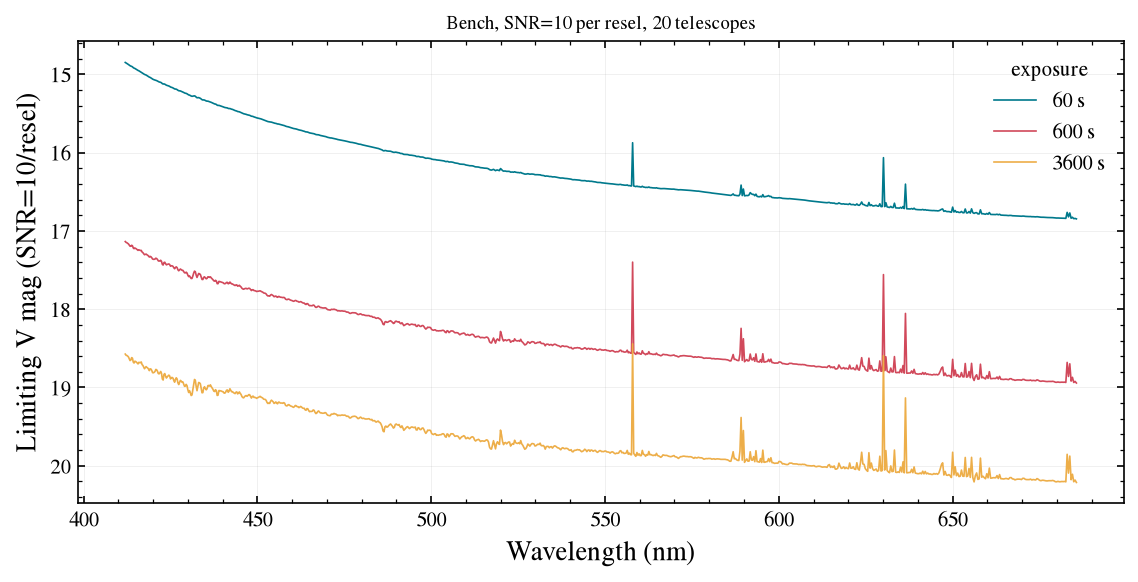

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_limiting_magnitude(bench, gstar, exptimes=[60, 600, 3600], snr=10, ax=ax)
ax.set_title("Bench, SNR=10 per resel, 20 telescopes", fontsize=9);

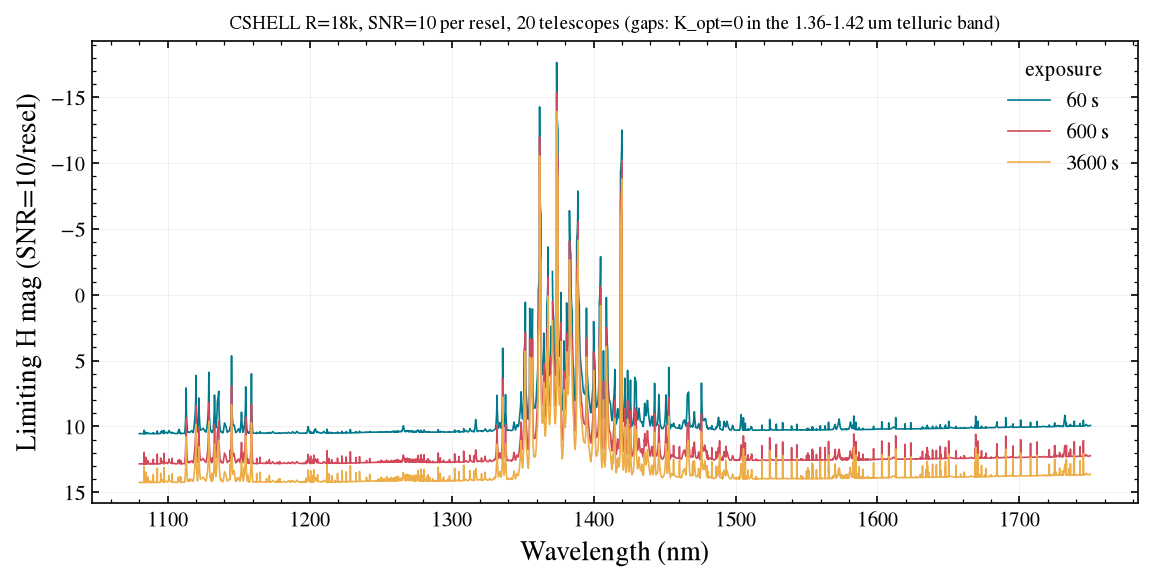

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
full = LFASTETC("cshell_r18000", n_telescopes=20)   # whole CSHELL range (many echelle settings)
plot_limiting_magnitude(full, kstar, exptimes=[60, 600, 3600], snr=10, ax=ax)
ax.set_title("CSHELL R=18k, SNR=10 per resel, 20 telescopes (gaps: K_opt=0 in the 1.36-1.42 um telluric band)", fontsize=9);

Each wavelength here is what *one* CSHELL echelle setting (~2.5e-3 lambda wide) would give; the
curve is not a single exposure. The structure is the throughput curve $K_{opt}$ (tellurics, fiber
coupling) on top of the sky.

## Scaling the number of telescopes

The 18 um fibers go through a 20-to-1 combiner: within one array $N_*$ and $N_{sky}$ both scale with
$N$ while the detector terms do not, so the gain is *better* than $\sqrt{N}$ when read noise or dark
current matter. Beyond 20 telescopes the ETC assumes one combiner input per 20 telescopes, co-added
incoherently (`telescopes_per_input=20`; the dotted curve shows an idealised single combiner). The
50 um fiber bypasses the combiner (one spectrum per telescope, SNR $\propto\sqrt N$) but has ~2x the
point-source coupling and a ~7.7x larger sky aperture.

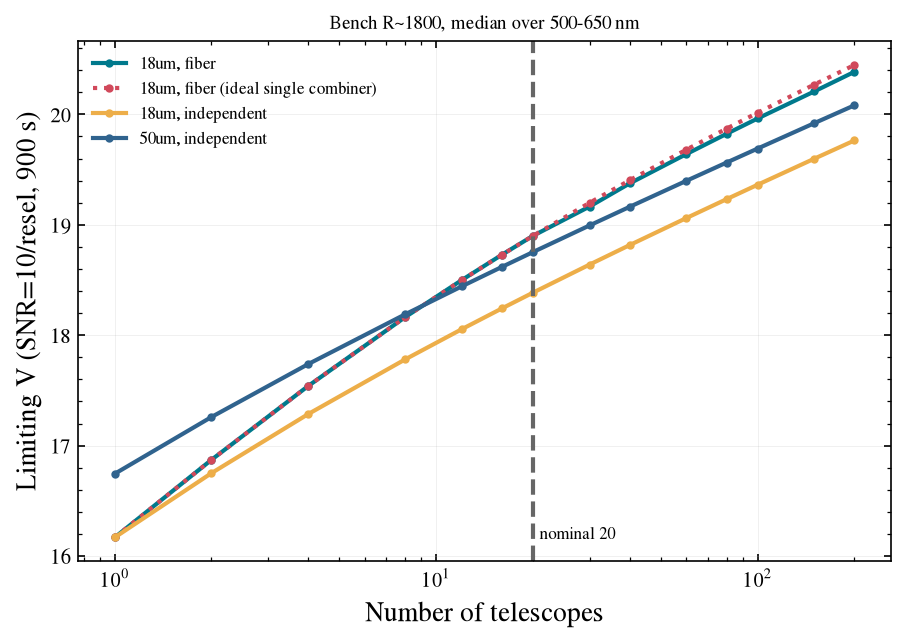

In [6]:
ns = np.array([1, 2, 4, 8, 12, 16, 20, 30, 40, 60, 80, 100, 150, 200])
rows = {}
for fiber, combine, tpi in (("18um", "fiber", 20), ("18um", "fiber", None), ("18um", "independent", 20), ("50um", "independent", 20)):
    if True:
        lim = []
        for n in ns:
            e = LFASTETC("bench_r1800", telescope=Telescope(n_telescopes=n, fiber=fiber, combine=combine, telescopes_per_input=tpi))
            lim.append(e.limiting_magnitude(gstar, exptime=900, snr=10, wavelength=(500, 650)))
        rows[(fiber, combine, tpi)] = np.array(lim)

fig, ax = plt.subplots(figsize=(7, 4.5))
for (fiber, combine, tpi), lim in rows.items():
    ax.plot(ns, lim, marker='o', ms=3, ls=':' if tpi is None else '-',
            label=f"{fiber}, {combine}" + (" (ideal single combiner)" if tpi is None else ""))
ax.set_xscale('log'); ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Limiting V (SNR=10/resel, 900 s)")
ax.axvline(20, color='0.4', ls='--'); ax.text(21, ax.get_ylim()[0]+0.2, "nominal 20", fontsize=8)
ax.legend(fontsize=8); ax.set_title("Bench R~1800, median over 500-650 nm", fontsize=9);

The same for CSHELL, where read noise (22 e$^-$) and dark current (0.5 e$^-$/s) are large, so the fiber combiner matters more:

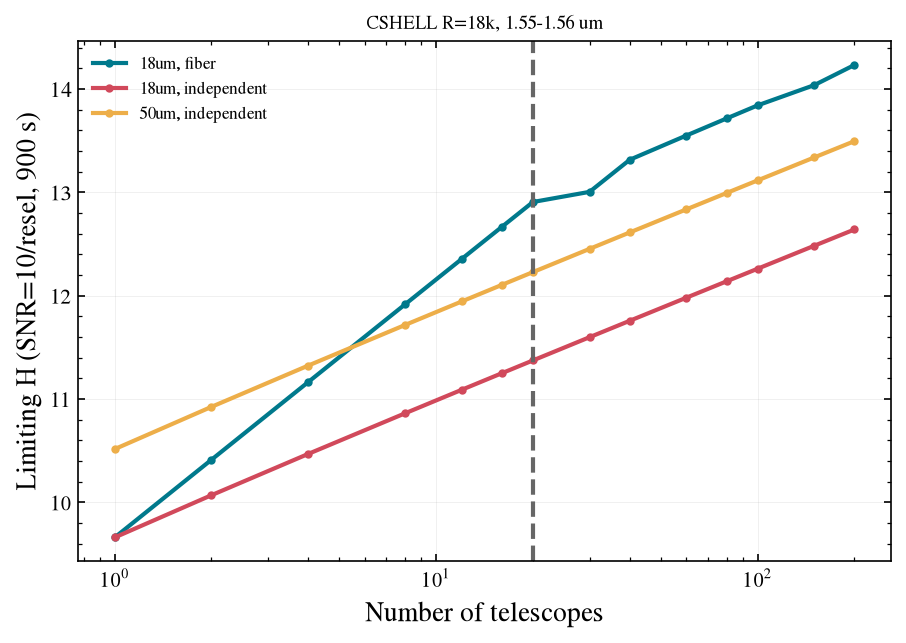

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for fiber, combine in (("18um", "fiber"), ("18um", "independent"), ("50um", "independent")):
    lim = [LFASTETC("cshell_r18000", telescope=Telescope(n_telescopes=n, fiber=fiber, combine=combine),
                    wavelength_min_nm=1550, wavelength_max_nm=1560).limiting_magnitude(kstar, 900, 10)
           for n in ns]
    ax.plot(ns, lim, marker='o', ms=3, label=f"{fiber}, {combine}")
ax.set_xscale('log'); ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Limiting H (SNR=10/resel, 900 s)")
ax.axvline(20, color='0.4', ls='--'); ax.legend(fontsize=8); ax.set_title("CSHELL R=18k, 1.55-1.56 um", fontsize=9);

## Dark time versus the bundled grey-time sky

The bundled SkyCalc table has the moon up (45 deg away, 45 deg altitude): scattered moonlight is
~57% of the 540-560 nm sky, giving V ~ 20.5 mag/arcsec$^2$, about 1 mag brighter than dark Kitt
Peak (V ~ 21.7-22.0 at zenith, Neugent & Massey 2010). A crude dark-time estimate is `Sky(scale=0.4)`
(this scales the airglow lines too, which is wrong in detail; generate a proper SkyCalc table for
real planning). The Bench becomes sky-limited at V > ~19.5, so this matters for the faint end.

In [8]:
from lfast_etc import Sky
for label, sky in (("grey (bundled)", Sky()), ("dark (x0.4)", Sky(scale=0.4))):
    e = LFASTETC("bench_r1800", n_telescopes=20, sky=sky)
    print(f"{label:15s}: V_lim(SNR=10, 900 s) = {e.limiting_magnitude(gstar, 900, 10, wavelength=(500, 650)):.2f}")

grey (bundled) : V_lim(SNR=10, 900 s) = 18.90
dark (x0.4)    : V_lim(SNR=10, 900 s) = 19.16


## Exposure time versus magnitude at fixed SNR

A compact way to read off survey speed.

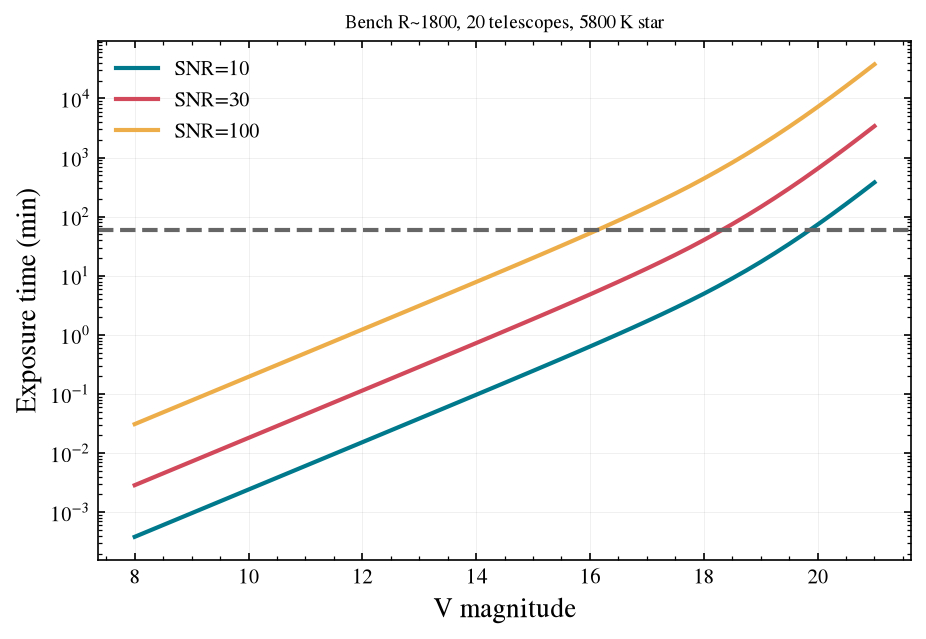

In [9]:
mags = np.linspace(8, 21, 53)
fig, ax = plt.subplots(figsize=(7, 4.5))
for snr_t in (10, 30, 100):
    t = bench.exptime_vs_mag(gstar, mags, snr=snr_t, wavelength=(500, 650))
    ax.plot(mags, t/60, label=f"SNR={snr_t}")
ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_ylabel("Exposure time (min)")
ax.axhline(60, color='0.4', ls='--'); ax.legend(); ax.set_title("Bench R~1800, 20 telescopes, 5800 K star", fontsize=9);